# Identifying Musical Style from Audio Features: A Case Study of Angine de Poitrine

**Course:** DT2470 Music Informatics

**Group Members:** Johanna Genander, Fanny Nyberg, Filip Svebeck

**Examiner:** Bobby Lee Townsend Sturm Jr.

## Research question
Can the unusual musical style of Angine de Poitrine (AdP) be identified from audio features alone, and which measurable characteristics, particularly rhythmic irregularity and microtonality, separate it from conventional rock?

## Hypotheses
- **H1 (rhythm):** AdP clips show higher inter-onset-interval variability and lower beat-tracking confidence / higher tempogram entropy than GTZAN rock.
- **H2 (pitch):** AdP clips deviate more from 12-tone equal temperament (12-TET); their fine-grained pitch-class histograms are flatter / have peaks off the semitone grid.
- **H3 (classification):** A linear classifier on rhythm and pitch features separates the two classes clearly above a majority-class baseline.

## Data
| Class | Source | Format | Target n |
|---|---|---|---|
| `adp` (positive) | 2 albums purchased on iTunes, sliced into 30 s segments | `.m4a` → `.wav` | ~100 |
| `rock` (negative) | GTZAN *rock* genre subset (Kaggle), already 30 s | `.wav` (22 050 Hz, mono) | 100 |

## Notebook Overview
Insert a table overview when the notebook is complete.

## 0. Setup

In [123]:
from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt

from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Reproducibility
SEED = 42
rng = np.random.default_rng(SEED)

# Audio settings
SR = 22050
SEG_SEC = 30
TARGET_DBFS = -20.0
MAX_SEG_PER_TRACK = 8

# General feature extraction
WIN_MS = 25
HOP_MS = 10

WIN = int(WIN_MS / 1000 * SR)
HOP = int(HOP_MS / 1000 * SR)

N_FFT = 2048
N_MFCC = 13

# Pitch analysis
PITCH_WIN = int(0.100 * SR)
PITCH_HOP = PITCH_WIN // 10

# Data paths
RAW_ADP = Path("raw-data/adp")
RAW_ROCK = Path("raw-data/rock")

WAV_ADP = Path("data/interim")
SEG_ADP = Path("data/processed")
CACHE = Path("cache")
FIGS = Path("figures")

for d in [WAV_ADP, SEG_ADP, CACHE, FIGS]:
    d.mkdir(parents=True, exist_ok=True)

## 1. Data Preparation

The dataset contains two classes:

- **Angine de Poitrine (AdP):** tracks from two purchased albums, converted to WAV and divided into 30-second segments.
- **Rock:** 100 pre-segmented 30-second excerpts from the GTZAN Rock dataset.

The goal is to construct a balanced dataset of approximately 200 clips. For the AdP material, the identity of the original track is retained so that segments from the same song can later be kept within the same cross-validation fold, preventing data leakage.

### 1.1 Convert AdP Audio to WAV

In [124]:
import subprocess

WAV_ADP.mkdir(parents=True, exist_ok=True)

adp_files = sorted(RAW_ADP.rglob("*.m4a"))

for src in adp_files:
    dst = WAV_ADP / f"{src.stem}.wav"

    if not dst.exists():
        subprocess.run(
            [
                "ffmpeg",
                "-y",
                "-i", str(src),
                "-ac", "1",
                "-ar", str(SR),
                str(dst)
            ],
            check=True,
            stdout=subprocess.DEVNULL,
            stderr=subprocess.DEVNULL
        )

All AdP recordings were converted to mono WAV at 22,050 Hz so that both datasets use the same audio format and sampling rate.

### 1.2 Split AdP Tracks Into 30-Second Segments
This is done because GTZAN consists of 30-second excerpts.

In [125]:
SEG_ADP.mkdir(parents=True, exist_ok=True)

segment_records = []

for wav_path in sorted(WAV_ADP.glob("*.wav")):
    y, sr = librosa.load(wav_path, sr=SR, mono=True)

    samples_per_segment = int(SEG_SEC * SR)
    n_segments = len(y) // samples_per_segment

    # Limit number of segments per original track
    n_keep = min(n_segments, MAX_SEG_PER_TRACK)

    if n_keep == 0:
        continue

    # Evenly spread selected segments across the track
    selected = np.linspace(
        0,
        n_segments - 1,
        n_keep,
        dtype=int
    )

    for seg_idx in selected:
        start = seg_idx * samples_per_segment
        end = start + samples_per_segment
        clip = y[start:end]

        out_path = SEG_ADP / f"{wav_path.stem}_seg{seg_idx:02d}.wav"
        sf.write(out_path, clip, SR)

        segment_records.append({
            "path": str(out_path),
            "label": 1,
            "label_name": "adp",
            "source_track": wav_path.stem,
            "segment_idx": seg_idx
        })

### 1.3 Index the GTZAN Rock Clips

In [126]:
rock_files = sorted(RAW_ROCK.rglob("*.wav"))[:100]

rock_records = []

for path in rock_files:
    rock_records.append({
        "path": str(path),
        "label": 0,
        "label_name": "rock",
        "source_track": path.stem,
        "segment_idx": 0
    })

### 1.4 Build the Dataset Manifest

In [127]:
manifest = pd.DataFrame(segment_records + rock_records)

manifest.insert(
    0,
    "clip_id",
    [f"clip_{i:03d}" for i in range(len(manifest))]
)

manifest.groupby("label_name").agg(
    n_clips=("clip_id", "count"),
    n_tracks=("source_track", "nunique")
)

,n_clips,n_tracks
label_name,,
adp,96,12
rock,100,100


The final dataset contains 196 audio excerpts: 96 Angine de Poitrine (AdP) segments derived from 12 original tracks and 100 GTZAN Rock excerpts. The classes are therefore approximately balanced. Since multiple AdP segments originate from the same track, the original track identity is retained for grouped cross-validation to prevent segments from the same recording appearing in both training and test sets.

## 2. Feature Extraction

Each feature extractor takes a waveform as input and returns a fixed-length set of scalar features. Features are grouped into three families:

- `rhy_`: rhythmic features
- `pit_`: pitch and tonal features
- `tim_`: timbral features

Many audio features are initially computed frame-by-frame over time. These are therefore summarized using statistics such as the mean, standard deviation, coefficient of variation, or entropy to obtain one fixed-length feature vector per 30-second clip.

The feature design is guided by the project hypotheses. Rhythmic features are used to investigate rhythmic irregularity, pitch-related features are used to investigate microtonality and tonal structure, and timbral features provide a conventional MIR baseline and help identify whether classification is driven by general recording or instrumentation differences rather than the hypothesized musical characteristics.

### 2.1 Shared Helper Functions

Several helper functions are used across the feature extraction pipeline. These include frame-based zero-crossing and spectral-centroid calculations, pitch-frequency conversion, peak selection in the time-frequency representation, audio loading and normalization, entropy calculation, and dynamic tempo estimation.

All clips are loaded as mono audio at 22,050 Hz and RMS-normalized before feature extraction to reduce loudness differences between the two datasets as a potential classification cue.


In [128]:
def zero_crossings_per_frame(x, frame_size, hop_size):
    """Return the number of sign changes in each complete frame of x."""
    x = np.asarray(x)
    crossings = []
    for start in range(0, len(x) - frame_size + 1, hop_size):
        frame = x[start:start + frame_size]
        signs = np.where(frame >= 0, 1, -1)
        crossings.append(np.count_nonzero(signs[:-1] != signs[1:]))
    return np.asarray(crossings, dtype=int)

def spectral_centroid_per_frame(x, frame_size, hop_size, sample_rate):
    """Return spectral centroids in Hz; silent frames receive a value of 0 Hz."""
    x = np.asarray(x, dtype=np.float64)
    frequencies = np.fft.rfftfreq(frame_size, d=1 / sample_rate)
    centroids = []
    for start in range(0, len(x) - frame_size + 1, hop_size):
        magnitude = np.abs(np.fft.rfft(x[start:start + frame_size]))
        denominator = magnitude.sum()
        centroids.append(np.dot(frequencies, magnitude) / denominator if denominator > 0 else 0.0)
    return np.asarray(centroids, dtype=np.float64)

# Equation 3.2 from Müller, 2015, Fundamentals of Music Processing
def f_pitch(p):
    """Convert MIDI pitch number to frequency in Hz."""
    return 440 * 2 ** ((p - 69) / 12)

def find_anchors(Sdb, sr, hop_length, dT=0.100, n_bands=25):
    """Loudest point in each dT x dF box, as (frame, bin) indices."""
    n_bins, n_frames = Sdb.shape
    dt_frames = int(round(dT * sr / hop_length))
    band_edges = np.linspace(0, n_bins, n_bands + 1).astype(int)

    t_idx, f_idx, db = [], [], []
    for t0 in range(0, n_frames, dt_frames):
        t1 = min(t0 + dt_frames, n_frames)
        for b in range(n_bands):
            f0, f1 = band_edges[b], band_edges[b + 1]
            box = Sdb[f0:f1, t0:t1]
            if box.size == 0:
                continue
            k, n = np.unravel_index(np.argmax(box), box.shape)
            t_idx.append(t0 + n)
            f_idx.append(f0 + k)
            db.append(box[k, n])
    return np.array(t_idx), np.array(f_idx), np.array(db)

def load_clip(path, target_dbfs=TARGET_DBFS):
    """Load a clip and RMS-normalise it, so loudness cannot act as a class cue."""
    y, _ = librosa.load(path, sr=SR, mono=True)
    y = librosa.util.fix_length(y, size=int(SEG_SEC * SR))
    rms = np.sqrt(np.mean(y ** 2)) + 1e-12
    y = y * (10 ** (target_dbfs / 20) / rms)
    peak = np.max(np.abs(y))
    return y / peak if peak > 1.0 else y # guard against clipping

def entropy(p):
    """Shannon entropy (bits) of a non-negative vector, normalised to sum 1."""
    p = np.clip(np.asarray(p, dtype=float), 0, None)
    total = p.sum()
    if total <= 0:
        return np.nan
    p = p[p > 0] / total
    return float(-(p * np.log2(p)).sum())


def dynamic_tempo(oenv):
    """Frame-wise tempo curve; the function moved between librosa versions."""
    try:
        return librosa.feature.rhythm.tempo(onset_envelope=oenv, sr=SR, hop_length=HOP, aggregate=None)
    except AttributeError:
        return librosa.beat.tempo(onset_envelope=oenv, sr=SR, hop_length=HOP, aggregate=None)

### 2.2 Rhythm Features

Rhythmic features are extracted to test whether Angine de Poitrine exhibits greater rhythmic irregularity than conventional rock.

Onsets are detected from the onset-strength envelope and used to calculate inter-onset intervals (IOIs). The primary feature for the rhythmic-irregularity hypothesis is the coefficient of variation of the IOIs (`rhy_ioi_cv`):

$$
CV_{\mathrm{IOI}} = \frac{\sigma_{\mathrm{IOI}}}{\mu_{\mathrm{IOI}}}
$$

Using the coefficient of variation rather than the standard deviation alone reduces the influence of overall tempo. Additional descriptors include tempo variability, onset rate, IOI entropy, pulse clarity, tempogram entropy, and deviation of detected onsets from the estimated beat grid.

In [129]:
def rhythm_features(y):
    oenv = librosa.onset.onset_strength(y=y, sr=SR, hop_length=HOP)
    f = {}

    tempo, beats = librosa.beat.beat_track(onset_envelope=oenv, sr=SR, hop_length=HOP, units="time")
    f["rhy_tempo"]      = float(np.atleast_1d(tempo)[0])
    f["rhy_beat_count"] = float(len(beats))
    f["rhy_tempo_std"]  = float(np.std(dynamic_tempo(oenv))) # tempo drift within the clip

    onsets = librosa.onset.onset_detect(onset_envelope=oenv, sr=SR, hop_length=HOP, units="time")
    ioi = np.diff(onsets)
    f["rhy_onset_rate"] = len(onsets) / SEG_SEC
    if len(ioi) >= 3:
        f["rhy_ioi_mean"]    = float(np.mean(ioi))
        f["rhy_ioi_std"]     = float(np.std(ioi))
        f["rhy_ioi_cv"]      = float(np.std(ioi) / (np.mean(ioi) + 1e-9))
        f["rhy_ioi_entropy"] = entropy(np.histogram(ioi, bins=20, range=(0, 2))[0])
    else:
        f.update(rhy_ioi_mean=np.nan, rhy_ioi_std=np.nan,
                 rhy_ioi_cv=np.nan, rhy_ioi_entropy=np.nan)

    ac = librosa.autocorrelate(oenv, max_size=len(oenv) // 2)
    ac = ac / (ac[0] + 1e-9)
    lag_min = int(round(0.25 * SR / HOP)) # ignore lags above 240 BPM
    f["rhy_pulse_clarity"] = float(ac[lag_min:].max()) if len(ac) > lag_min else np.nan

    tgram = librosa.feature.tempogram(onset_envelope=oenv, sr=SR, hop_length=HOP)
    f["rhy_tempogram_entropy"] = entropy(np.abs(tgram).mean(axis=1))

    if len(beats) > 2 and len(onsets) > 0:
        dev = np.abs(onsets[:, None] - beats[None, :]).min(axis=1)
        f["rhy_beat_sync_dev"] = float(np.mean(dev) / (np.median(np.diff(beats)) + 1e-9))
    else:
        f["rhy_beat_sync_dev"] = np.nan

    f["rhy_onset_env_mean"] = float(np.mean(oenv))
    f["rhy_onset_env_std"]  = float(np.std(oenv))
    return f

### 2.3 Pitch and Tonal Features

Pitch-related features are used to investigate harmonic structure and possible microtonality.

A log-frequency representation is first constructed by pooling spectral energy into MIDI pitch bands. These bands are then folded into 12 pitch classes to form a chromagram. Chroma statistics describe the distribution and stability of pitch classes across each clip.

In [130]:
_F_COEF = np.arange(PITCH_WIN // 2 + 1) * SR / PITCH_WIN
_PITCH_MASKS = [((_F_COEF >= f_pitch(p - 0.5)) & (_F_COEF < f_pitch(p + 0.5)))
                for p in range(128)]


def log_freq_spec(X):
    """Lab 03, part 2.2, eq 3.3-3.4: pool STFT power into MIDI pitch bands."""
    power = np.abs(X) ** 2
    return np.array([power[m].sum(axis=0) if m.any() else np.zeros(X.shape[1])
                     for m in _PITCH_MASKS])


def chromagram(Y):
    """Lab 03, part 2.3, eq 3.6."""
    chroma = np.zeros((12, Y.shape[1]))
    for p in range(128):
        chroma[p % 12] += Y[p]
    return chroma


def log_compress(v, gamma=100):
    """Lab 03, part 2.3, eq 3.8."""
    return np.log(1 + gamma * v)

#### Microtonality Measures

Microtonality is evaluated by measuring the deviation of estimated pitches from the nearest pitch in 12-tone equal temperament (12-TET).

Two complementary approaches are retained:

1. **Spectral grid concentration**, which measures how strongly prominent spectral peaks align to a common semitone grid.
2. **YIN-based pitch deviation**, which estimates the fundamental frequency and measures its mean distance from the nearest 12-TET semitone in cents.

The YIN-based measure (`pit_yin_dev_mean`) is treated as the primary feature for the microtonality hypothesis because spectral peak-based measures may also be affected by distortion, percussion, and spectral density.

In [131]:
def _parabolic_refine(col_db, k):
    """Sub-bin peak position by fitting a parabola through bins k-1, k, k+1."""
    if k <= 0 or k >= len(col_db) - 1:
        return 0.0
    a, b, c = col_db[k - 1], col_db[k], col_db[k + 1]
    denom = a - 2 * b + c
    return 0.0 if denom == 0 else float(np.clip(0.5 * (a - c) / denom, -0.5, 0.5))


def cents_from_semitone_grid(freqs_hz, tuning_semitones):
    """Distance in cents (0..50) from each frequency to the nearest 12-TET semitone."""
    cents = 1200 * np.log2(np.asarray(freqs_hz) / 440.0) - 100 * tuning_semitones
    return np.abs(((cents + 50) % 100) - 50)


def grid_concentration(freqs_hz):
    """Circular statistics on the 100-cent semitone circle.

    Returns (R, offset_cents, mean_abs_deviation). R is tuning-invariant by
    construction: 1 means every peak lands on one common semitone grid, 0 means
    the peaks are spread evenly and there is no grid to speak of. Measuring the
    deviation only AFTER removing the clip's own offset matters, no real
    recording sits exactly at A440, and an uncorrected offset alone pushes the
    deviation to chance level.
    """
    cents = 1200 * np.log2(np.asarray(freqs_hz) / 440.0)
    ang = 2 * np.pi * ((cents % 100) / 100.0)
    C, S = np.cos(ang).mean(), np.sin(ang).mean()
    R = float(np.hypot(C, S))
    offset = float(np.arctan2(S, C) / (2 * np.pi) * 100)
    dev = float(np.abs(((cents - offset + 50) % 100) - 50).mean())
    return R, offset, dev


def tonal_features(y):
    f = {}

    tuning = float(librosa.estimate_tuning(y=y, sr=SR))
    f["pit_tuning_offset"] = tuning

    X = librosa.stft(y, n_fft=PITCH_WIN, win_length=PITCH_WIN,
                     hop_length=PITCH_HOP, window="hann")
    Y = log_freq_spec(X)
    chroma = log_compress(chromagram(Y))
    chroma_mean = chroma.mean(axis=1)
    for i, v in enumerate(chroma_mean):
        f[f"pit_chroma_{i:02d}"] = float(v)
    f["pit_chroma_entropy"] = entropy(chroma_mean) # high -> no tonal centre
    f["pit_chroma_std"] = float(chroma.std(axis=1).mean())

    Sdb = librosa.amplitude_to_db(np.abs(X), ref=np.max)
    t_idx, f_idx, db = find_anchors(Sdb, SR, PITCH_HOP)
    bin_hz = SR / PITCH_WIN
    keep = np.flatnonzero((db > -40) & (f_idx > 2) & (f_idx < Sdb.shape[0] - 3))
    peaks = np.array([(f_idx[i] + _parabolic_refine(Sdb[:, t_idx[i]], f_idx[i])) * bin_hz
                      for i in keep]) if len(keep) > 20 else np.array([])
    peaks = peaks[(peaks > 80) & (peaks < 1500)]      # where pitched content lives
    if len(peaks) > 20:
        R, offset_cents, dev = grid_concentration(peaks)
        f["pit_grid_concentration"] = R
        f["pit_peak_tuning_cents"] = offset_cents
        f["pit_peak_dev_mean"]     = dev
    else:
        f.update(pit_grid_concentration=np.nan, pit_peak_tuning_cents=np.nan,
                 pit_peak_dev_mean=np.nan)

    f0 = librosa.yin(y, fmin=65, fmax=2000, sr=SR, frame_length=N_FFT, hop_length=HOP)
    rms = librosa.feature.rms(y=y, hop_length=HOP)[0][:len(f0)]
    voiced = np.isfinite(f0) & (f0 > 0) & (rms > np.percentile(rms, 50))
    f["pit_voiced_fraction"] = float(voiced.mean())
    if voiced.sum() > 10:
        dev = cents_from_semitone_grid(f0[voiced], tuning)
        f["pit_yin_dev_mean"] = float(np.mean(dev))
        f["pit_yin_dev_std"]  = float(np.std(dev))
        f["pit_f0_median"] = float(np.median(f0[voiced]))
        f["pit_f0_iqr"]    = float(np.subtract(*np.percentile(f0[voiced], [75, 25])))
    else:
        f.update(pit_yin_dev_mean=np.nan, pit_yin_dev_std=np.nan,
                 pit_f0_median=np.nan, pit_f0_iqr=np.nan)
    return f

### 2.4 Timbre Features

Timbral features are included to provide a conventional MIR representation of the recordings and to determine whether classification is driven primarily by rhythm and pitch or by broader differences in instrumentation, production, and spectral characteristics.

The extracted timbral descriptors include zero-crossing rate, spectral centroid, 13 MFCC coefficients, spectral bandwidth, rolloff, flatness, and RMS energy. Frame-level descriptors are summarized using their mean and standard deviation.

In [132]:
def timbre_features(y):
    f = {}

    zc = zero_crossings_per_frame(y, WIN, HOP)
    sc = spectral_centroid_per_frame(y, WIN + WIN % 2, HOP, SR)
    f["tim_zc_mean"], f["tim_zc_std"] = float(zc.mean()), float(zc.std())
    f["tim_sc_mean"], f["tim_sc_std"] = float(sc.mean()), float(sc.std())

    mfcc = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=N_MFCC, n_fft=N_FFT,
                                win_length=WIN, hop_length=HOP, window="hann")
    for i in range(N_MFCC):
        f[f"tim_mfcc{i:02d}_mean"] = float(mfcc[i].mean())
        f[f"tim_mfcc{i:02d}_std"]  = float(mfcc[i].std())

    for name, vals in [
        ("bandwidth", librosa.feature.spectral_bandwidth(y=y, sr=SR, hop_length=HOP)[0]),
        ("rolloff",   librosa.feature.spectral_rolloff(y=y, sr=SR, hop_length=HOP)[0]),
        ("flatness",  librosa.feature.spectral_flatness(y=y, hop_length=HOP)[0]),
        ("rms",       librosa.feature.rms(y=y, hop_length=HOP)[0]),
    ]:
        f[f"tim_{name}_mean"] = float(vals.mean())
        f[f"tim_{name}_std"]  = float(vals.std())
    return f

### 2.5 Extract Features for All Clips

The three feature families are extracted for every clip in the dataset and combined with the dataset manifest. The resulting table contains one row per 30-second clip and one column per extracted feature.

Feature extraction is cached to disk so that the complete audio analysis does not need to be repeated every time the notebook is executed.

In [133]:
def extract_all(path):
    y = load_clip(path)
    out = {}
    for fn in (rhythm_features, tonal_features, timbre_features):
        try:
            out.update(fn(y))
        except Exception as e:
            print(f"  ! {fn.__name__} failed on {Path(path).name}: {e}")
    return out


def build_features(manifest, cache=CACHE / "features.csv", force=False):
    if cache.exists() and not force:
        print(f"Loaded cached features from {cache}")
        return pd.read_csv(cache)

    rows = []
    for n, r in enumerate(manifest.itertuples(), 1):
        if n % 20 == 0 or n == 1:
            print(f"  {n}/{len(manifest)}")
        rows.append({"clip_id": r.clip_id, **extract_all(r.path)})

    feats = manifest.merge(pd.DataFrame(rows), on="clip_id")
    feats.to_csv(cache, index=False)
    print(f"Saved {feats.shape[0]} x {feats.shape[1]} to {cache}")
    return feats

features = build_features(manifest)

FEATURE_COLS = [
    c for c in features.columns
    if c.startswith(("rhy_", "pit_", "tim_"))
]

print(
    f"{len(FEATURE_COLS)} features: "
    f"{sum(c.startswith('rhy_') for c in FEATURE_COLS)} rhythm, "
    f"{sum(c.startswith('pit_') for c in FEATURE_COLS)} pitch/tonal, "
    f"{sum(c.startswith('tim_') for c in FEATURE_COLS)} timbre"
)

Loaded cached features from cache/features.csv
74 features: 13 rhythm, 23 pitch/tonal, 38 timbre


## 3. Analysis

This section examines how the extracted audio features differ between Angine de Poitrine and conventional rock before any classification model is trained.

The analysis focuses first on the two hypothesis-driven features:

- `rhy_ioi_cv`, representing rhythmic irregularity.
- `pit_yin_dev_mean`, representing mean pitch deviation from the nearest 12-TET semitone.

Additional features are then compared to determine which musical dimensions show the strongest differences between the two groups. This exploratory analysis also helps identify potential dataset or recording-related confounds before classification.

### 3.1 Class-Conditional Feature Distributions

The distributions of the two primary hypothesis features are compared between the AdP and rock classes.

For H1, a higher `rhy_ioi_cv` indicates greater variability in inter-onset intervals and therefore greater rhythmic irregularity.

For H2, a higher `pit_yin_dev_mean` indicates that estimated pitches lie further from the nearest 12-tone equal-tempered semitone.

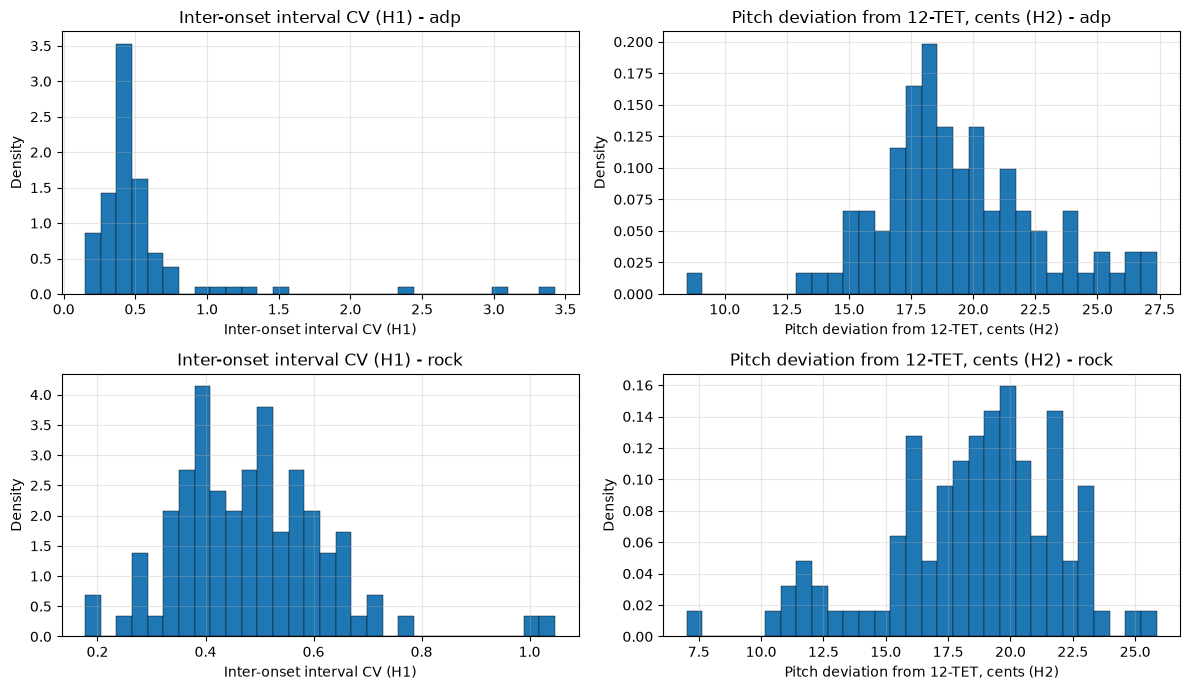

In [134]:
KEY_FEATURES = [
    "rhy_ioi_cv",
    "pit_yin_dev_mean"
]

KEY_LABELS = [
    "Inter-onset interval CV (H1)",
    "Pitch deviation from 12-TET, cents (H2)"
]

fig, axs = plt.subplots(2, len(KEY_FEATURES), figsize=(12, 7))

for col, (feat, label) in enumerate(zip(KEY_FEATURES, KEY_LABELS)):
    for row, cls in enumerate(["adp", "rock"]):
        values = features.loc[
            features["label_name"] == cls,
            feat
        ].dropna()

        ax = axs[row, col]

        ax.hist(
            values,
            bins=30,
            density=True,
            edgecolor="black",
            linewidth=0.3
        )

        ax.set_title(f"{label} - {cls}")
        ax.set_xlabel(label)
        ax.set_ylabel("Density")
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [135]:
for feat, label in zip(KEY_FEATURES, KEY_LABELS):
    for cls in ["adp", "rock"]:
        values = features.loc[
            features["label_name"] == cls,
            feat
        ].dropna()

        print(
            f"{cls:5s} {label:40s} "
            f"mean={values.mean():.3f} "
            f"std={values.std():.3f} "
            f"median={values.median():.3f}"
        )

adp   Inter-onset interval CV (H1)             mean=0.554 std=0.488 median=0.447
rock  Inter-onset interval CV (H1)             mean=0.485 std=0.141 median=0.481
adp   Pitch deviation from 12-TET, cents (H2)  mean=19.384 std=3.275 median=18.871
rock  Pitch deviation from 12-TET, cents (H2)  mean=18.509 std=3.446 median=19.047
